In [ ]:
import pandas as pd
import numpy as np

# Switzerland

In [2]:
cantons = [
    "Aargau", "Appenzell Ausserrhoden", "Appenzell Innerrhoden", "Basel-Landschaft", "Basel-Stadt",
    "Bern", "Fribourg", "Geneva", "Glarus", "Graubünden", "Jura", "Lucerne", "Neuchâtel", "Nidwalden",
    "Obwalden", "Schaffhausen", "Schwyz", "Solothurn", "St. Gallen", "Thurgau", "Ticino", "Uri",
    "Valais", "Vaud", "Zug", "Zurich"
]

years = [2030, 2040, 2050]

## Yearly

### Temperature

In [3]:
data = {
    "time": [],
    "area": [],
    "location": [],
    "temperature": [],
    "unit": []
}

for year in years:
    for canton in cantons:
        data["time"].append(f"{year}-12-31T23:00")
        data["area"].append("switzerland")
        data["location"].append(canton)
        # Temperature anomaly increases with years: 2030=1.0, 2040=1.7, 2050=2.4 (+ some random noise)
        anomaly_base = 1.0 + years.index(year) * 0.7
        data["temperature"].append(round(anomaly_base + np.random.uniform(-0.2, 0.2), 1))
        data["unit"].append("c")

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/switzerland_temperature_per_canton_yearly.csv", index=False)

In [4]:
data = {
    "time": [],
    "area": [],
    "temperature": [],
    "unit": []
}

for year in years:
    data["time"].append(f"{year}-12-31T23:00")
    data["area"].append("switzerland")
    # Temperature anomaly increases with years: 2030=1.0, 2040=1.7, 2050=2.4 (+ some random noise)
    anomaly_base = 1.0 + years.index(year) * 0.7
    data["temperature"].append(round(anomaly_base + np.random.uniform(-0.2, 0.2), 1))
    data["unit"].append("c")

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/switzerland_temperature_yearly.csv", index=False)

### PV, Wind Power

In [5]:
# Dummy percentage change data for PV and wind power
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}
# Dummy percentage change data for hydropower
hydro_proj = {2030: -2, 2040: -3, 2050: -4}

yearly_pv_percent_change = []
yearly_wind_percent_change = []
yearly_hydro_percent_change = []
for year in years:
    # Add random noise between -2% and +2% for each canton/month
    pv_noise = np.random.uniform(-2, 2)
    wind_noise = np.random.uniform(-2, 2)
    hydro_noise = np.random.uniform(-1, 1)
    pv_change = round(pv_proj[year] + pv_noise)
    wind_change = round(wind_proj[year] + wind_noise)
    hydro_change = round(hydro_proj[year] + hydro_noise)
    yearly_pv_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "switzerland",
        "pv": pv_change,
        "unit": "%",
    })
    yearly_wind_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "switzerland",
        "wind_power": wind_change,
        "unit": "%",
    })
    yearly_hydro_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "switzerland",
        "hydropower": hydro_change,
        "unit": "%",
    })

# Convert to DataFrame if needed
yearly_pv_percent_change_df = pd.DataFrame(yearly_pv_percent_change)
yearly_wind_percent_change_df = pd.DataFrame(yearly_wind_percent_change)
yearly_hydro_percent_change_df = pd.DataFrame(yearly_hydro_percent_change)

# Save to CSV
yearly_pv_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_pv_percent_change_yearly.csv", index=False)
yearly_wind_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_wind_percent_change_yearly.csv", index=False)
yearly_hydro_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_hydro_percent_change_yearly.csv", index=False)

In [6]:
yearly_hydro_percent_change_df

,time,area,hydropower,unit
0,2030-12-31T23:00,switzerland,-2,%
1,2040-12-31T23:00,switzerland,-2,%
2,2050-12-31T23:00,switzerland,-3,%


## Monthly

### PV, Wind Power

In [7]:
# Dummy percentage change data for PV, wind power, and hydropower
hydro_proj = {2030: 1, 2040: 0, 2050: -1}
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}

monthly_pv_percent_change = []
monthly_wind_percent_change = []
monthly_hydro_percent_change = []
months = range(1, 13)  # January to December
for year in years:
    for month in months:
        last_day = pd.Period(f"{year}-{month}").days_in_month
        # Add random noise between -2% and +2% for each canton/month, with seasonal variation
        # Example: use a sinusoidal pattern to simulate seasonal effect
        seasonal_factor = np.sin((month - 1) / 12 * 2 * np.pi)
        pv_noise = np.random.uniform(-2, 2) + seasonal_factor
        wind_noise = np.random.uniform(-2, 2) + 0.5 * seasonal_factor
        hydro_noise = np.random.uniform(-1, 1)
        pv_change = round(pv_proj[year] + pv_noise)
        wind_change = round(wind_proj[year] + wind_noise)
        hydro_change = round(hydro_proj[year] + hydro_noise)
        monthly_pv_percent_change.append({
            "time": f"{year}-{month:02d}-{last_day}T23:00",
            "area": "switzerland",
            "pv": pv_change,
            "unit": "%",
        })
        monthly_wind_percent_change.append({
            "time": f"{year}-{month:02d}-{last_day}T23:00",
            "area": "switzerland",
            "wind_power": wind_change,
            "unit": "%",
        })
        monthly_hydro_percent_change.append({
            "time": f"{year}-{month:02d}-{last_day}T23:00",
            "area": "switzerland",
            "hydropower": hydro_change,
            "unit": "%",
        })

# Convert to DataFrame if needed
monthly_pv_percent_change_df = pd.DataFrame(monthly_pv_percent_change)
monthly_wind_percent_change_df = pd.DataFrame(monthly_wind_percent_change)
monthly_hydro_percent_change_df = pd.DataFrame(monthly_hydro_percent_change)

# Save to CSV
monthly_pv_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_pv_percent_change_monthly.csv", index=False)
monthly_wind_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_wind_percent_change_monthly.csv", index=False)
monthly_hydro_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_hydro_percent_change_monthly.csv", index=False)

### Heating and Cooling Degree Days

In [8]:
base_temp = 18  # base temperature in Celsius

months = range(1, 13)
# Number of days per month where heating/cooling is needed (example for Switzerland)
# Assume heating is needed when avg temp < base_temp, cooling when avg temp > base_temp+4
# Here we use a simple illustrative pattern for each month

hdd_days_pattern = [31, 28, 31, 25, 10, 3, 1, 2, 7, 20, 28, 31]  # days needing heating
cdd_days_pattern = [0, 0, 0, 2, 7, 15, 25, 22, 8, 1, 0, 0]       # days needing cooling

# Assume HDD decreases and CDD increases over time due to warming
hdd_trend = {2030: 1.0, 2040: 0.92, 2050: 0.85}
cdd_trend = {2030: 1.0, 2040: 1.15, 2050: 1.3}

data = {
    "time": [],
    "area": [],
    "heating_degree_days": [],
    "cooling_degree_days": []
}

for year in years:
    for i, month in enumerate(months):
        hdd = int(hdd_days_pattern[i] * hdd_trend[year])
        cdd = int(cdd_days_pattern[i] * cdd_trend[year])
        last_day = pd.Period(f"{year}-{month}").days_in_month
        data["time"].append(f"{year}-{month:02d}-{last_day}T23:00")
        data["area"].append("switzerland")
        data["heating_degree_days"].append(hdd)
        data["cooling_degree_days"].append(cdd)

national_hdd_cdd_df = pd.DataFrame(data)
national_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_hdd_cdd_monthly.csv", index=False)

<Axes: >

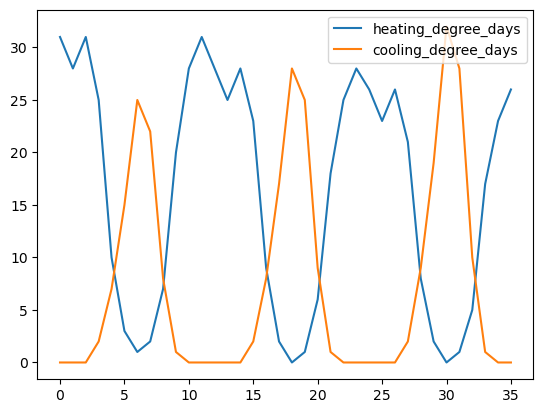

In [9]:
national_hdd_cdd_df.plot()

# Europe

In [10]:
EUROPEAN_COUNTRIES = [
    "Albania",
    "Austria",
    "Bosnia and Herzegovina",
    "Belgium",
    "Bulgaria",
    "Switzerland",
    "Czech Republic",
    "Germany",
    "Denmark",
    "Estonia",
    "Spain",
    "Finland",
    "France",
    "Greece",
    "Croatia",
    "Hungary",
    "Ireland",
    "Italy",  # several bidding zones
    "Lithuania",
    "Latvia",
    "Montenegro",
    "Macedonia",
    "Netherlands",
    "Norway",  # several bidding zones
    "Poland",
    "Portugal",
    "Romania",
    "Serbia",
    "Sweden",  # several bidding zones
    "Slovenia",
    "Slovakia",
    "United Kingdom",
]
years = [2030, 2040, 2050]

## Yearly

## Temperature

In [11]:
data = {
    "time": [],
    "area": [],
    "location": [],
    "temperature": [],
    "unit": []
}

for i, year in enumerate(years):
    # Set anomaly baseline and increment (e.g., 1.0°C in 2030, 1.7°C in 2040, 2.4°C in 2050)
    anomaly_base = 1.0 + i * 0.7
    for country in EUROPEAN_COUNTRIES:
        # Add some random noise for each country
        anomaly = round(anomaly_base + np.random.uniform(-0.2, 0.2), 1)
        data["time"].append(f"{year}-12-31T23:00")
        data["area"].append("europe")
        data["location"].append(country)
        data["temperature"].append(anomaly)
        data["unit"].append("c")

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/europe_temperature_per_country_yearly.csv", index=False)

In [12]:
data = {
    "time": [],
    "area": [],
    "temperature": [],
    "unit": []
}

for i, year in enumerate(years):
    # Set anomaly baseline and increment (e.g., 1.5°C in 2030, 2.2°C in 2040, 2.9°C in 2050)
    anomaly_base = 1.5 + i * 0.7
    # Add some random noise for each country
    anomaly = round(anomaly_base + np.random.uniform(-0.2, 0.2), 1)
    data["time"].append(f"{year}-12-31T23:00")
    data["area"].append("europe")
    data["temperature"].append(anomaly)
    data["unit"].append("c")

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/europe_temperature_yearly.csv", index=False)

### PV, Wind Power

In [13]:
# Dummy percentage change data for PV and wind power
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}
# Dummy percentage change data for hydropower
hydro_proj = {2030: -2, 2040: -3, 2050: -4}

yearly_pv_percent_change = []
yearly_wind_percent_change = []
yearly_hydro_percent_change = []
for year in years:
    # Add random noise between -2% and +2% for each canton/month
    pv_noise = np.random.uniform(-2, 2)
    wind_noise = np.random.uniform(-2, 2)
    hydro_noise = np.random.uniform(-1, 1)
    pv_change = round(pv_proj[year] + pv_noise)
    wind_change = round(wind_proj[year] + wind_noise)
    hydro_change = round(hydro_proj[year] + hydro_noise)
    yearly_pv_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "europe",
        "pv": pv_change,
        "unit": "%",
    })
    yearly_wind_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "europe",
        "wind_power": wind_change,
        "unit": "%",
    })
    yearly_hydro_percent_change.append({
        "time": f"{year}-12-31T23:00",
        "area": "europe",
        "hydropower": hydro_change,
        "unit": "%",
    })

# Convert to DataFrame if needed
yearly_pv_percent_change_df = pd.DataFrame(yearly_pv_percent_change)
yearly_wind_percent_change_df = pd.DataFrame(yearly_wind_percent_change)
yearly_hydro_percent_change_df = pd.DataFrame(yearly_hydro_percent_change)

# Save to CSV
yearly_pv_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_pv_percent_change_yearly.csv", index=False)
yearly_wind_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_wind_percent_change_yearly.csv", index=False)
yearly_hydro_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_hydro_percent_change_yearly.csv", index=False)

In [14]:
yearly_hydro_percent_change_df

,time,area,hydropower,unit
0,2030-12-31T23:00,europe,-3,%
1,2040-12-31T23:00,europe,-2,%
2,2050-12-31T23:00,europe,-4,%


## Monthly

### PV, Wind Power

In [15]:
# Dummy percentage change data for PV, wind power, and hydropower
hydro_proj = {2030: 1, 2040: 0, 2050: -1}
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}

monthly_pv_percent_change = []
monthly_wind_percent_change = []
monthly_hydro_percent_change = []
for year in years:
    for month in months:
        # Add random noise between -2% and +2% for each canton/month, with seasonal variation
        # Example: use a sinusoidal pattern to simulate seasonal effect
        last_day = pd.Period(f"{year}-{month}").days_in_month
        seasonal_factor = np.sin((month - 1) / 12 * 2 * np.pi)
        pv_noise = np.random.uniform(-2, 2) + seasonal_factor
        wind_noise = np.random.uniform(-2, 2) + 0.5 * seasonal_factor
        hydro_noise = np.random.uniform(-1, 1)
        pv_change = round(pv_proj[year] + pv_noise)
        wind_change = round(wind_proj[year] + wind_noise)
        hydro_change = round(hydro_proj[year] + hydro_noise)
        monthly_pv_percent_change.append({
            "time": f"{year}-{month:02d}-{last_day}T23:00",
            "area": "europe",
            "pv": pv_change,
            "unit": "%",
        })
        monthly_wind_percent_change.append({
            "time": f"{year}-{month:02d}-{last_day}T23:00",
            "area": "europe",
            "wind_power": wind_change,
            "unit": "%",
        })
        monthly_hydro_percent_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "europe",
            "hydropower": hydro_change,
            "unit": "%",
        })

# Convert to DataFrame if needed
monthly_pv_percent_change_df = pd.DataFrame(monthly_pv_percent_change)
monthly_wind_percent_change_df = pd.DataFrame(monthly_wind_percent_change)
monthly_hydro_percent_change_df = pd.DataFrame(monthly_hydro_percent_change)

# Save to CSV
monthly_pv_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_pv_percent_change_monthly.csv", index=False)
monthly_wind_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_wind_percent_change_monthly.csv", index=False)
monthly_hydro_percent_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_hydro_percent_change_monthly.csv", index=False)

### Heating and Cooling Degree Days

In [16]:
base_temp = 18  # base temperature in Celsius

months = range(1, 13)
# Example patterns for Europe: number of days per month where heating/cooling is needed
# These are illustrative and can be adjusted for more realism per country/region

hdd_days_pattern = [28, 25, 28, 18, 7, 2, 0, 1, 5, 15, 22, 27]  # days needing heating
cdd_days_pattern = [0, 0, 0, 2, 8, 15, 25, 22, 10, 2, 0, 0]     # days needing cooling

# Assume HDD decreases and CDD increases over time due to warming
hdd_trend = {2030: 1.0, 2040: 0.92, 2050: 0.85}
cdd_trend = {2030: 1.0, 2040: 1.15, 2050: 1.3}

data = {
    "time": [],
    "area": [],
    "heating_degree_days": [],
    "cooling_degree_days": []
}

for year in years:
    for i, month in enumerate(months):
        hdd = int(hdd_days_pattern[i] * hdd_trend[year])
        cdd = int(cdd_days_pattern[i] * cdd_trend[year])
        last_day = pd.Period(f"{year}-{month}").days_in_month
        data["time"].append(f"{year}-{month:02d}-{last_day}T23:00")
        data["area"].append("europe")
        data["heating_degree_days"].append(hdd)
        data["cooling_degree_days"].append(cdd)

europe_hdd_cdd_df = pd.DataFrame(data)
europe_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/europe_hdd_cdd_monthly.csv", index=False)

<Axes: >

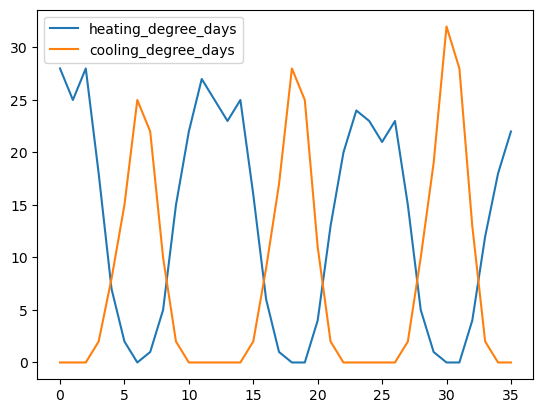

In [17]:
europe_hdd_cdd_df.plot()

# README

In [18]:
readme_md = """
# README

These are dummy datasets for Europe and Switzerland, simulating climate and renewable energy projections for the years 2030, 2040, and 2050. All relative quantities (anomalies, percentage changes) are relative to the 1991-2020 reference period, used as baseline.

---

## Europe

### Yearly

#### 1. `europe_temperature_per_country_yearly.csv`
- **Columns:** `time`, `area`, `location`, `temperature`, `unit`
- **Description:** Decadal temperature anomaly for each European country.
- **Example row:**
    `2030-12-31T23:00, europe, France, 1.8, c`

#### 2. `europe_temperature_yearly.csv`
- **Columns:** `time`, `area`, `temperature`, `unit`
- **Description:** Decadal average temperature anomaly for Europe as a whole.
- **Example row:**
    `2040-12-31T23:00, europe, 2.2, c`

#### 3. `europe_pv_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `pv`, `unit`
- **Description:** Decadal projected percent change in PV power generation for Europe.
- **Example row:**
    `2050-12-31T23:00, europe, 9, %`

#### 4. `europe_wind_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `wind_power`, `unit`
- **Description:** Decadal projected percent change in wind power generation for Europe.
- **Example row:**
    `2040-12-31T23:00, europe, 6, %`

#### 5. `europe_hydro_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `hydropower`, `unit`
- **Description:** Decadal projected percent change in hydropower generation for Europe.
- **Example row:**
    `2030-12-31T23:00, europe, -2, %`

### Monthly

#### 6. `europe_pv_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `pv`, `unit`
- **Description:** Decadal monthly projected percent change in PV power generation for Europe.
- **Example row:**
    `2050-06-30T23:00, europe, 10, %`

#### 7. `europe_wind_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `wind_power`, `unit`
- **Description:** Decadal monthly projected percent change in wind power generation for Europe.
- **Example row:**
    `2040-11-30T23:00, europe, 3, %`

#### 8. `europe_hydro_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `hydropower`, `unit`
- **Description:** Decadal monthly projected percent change in hydropower generation for Europe.
- **Example row:**
    `2040-12-31T23:00, europe, 0, %`

#### 9. `europe_hdd_cdd_monthly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`
- **Description:** Decadal monthly national heating and cooling degree days for Europe.
- **Example row:**
    `2050-01-31T23:00, europe, 23, 0`

---

## Switzerland

### Yearly

#### 1. `switzerland_temperature_per_canton_yearly.csv`
- **Columns:** `time`, `area`, `location`, `temperature`, `unit`
- **Description:** Decadal average temperature anomaly for each canton in Switzerland.
- **Example row:**
    `2040-12-31T23:00, switzerland, Geneva, 2.5, c`

#### 2. `switzerland_temperature_yearly.csv`
- **Columns:** `time`, `area`, `temperature`, `unit`
- **Description:** Decadal average temperature anomaly for Switzerland.
- **Example row:**
    `2040-12-31T23:00, switzerland, 2.5, c`

#### 3. `switzerland_pv_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `pv`, `unit`
- **Description:** Decadal projected percent change in PV power generation for Switzerland.
- **Example row:**
    `2050-12-31T23:00, switzerland, 8, %`

#### 4. `switzerland_wind_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `wind_power`, `unit`
- **Description:** Decadal projected percent change in wind power generation for Switzerland.
- **Example row:**
    `2030-12-31T23:00, switzerland, 5, %`

#### 5. `switzerland_hydro_percent_change_yearly.csv`
- **Columns:** `time`, `area`, `hydropower`, `unit`
- **Description:** Decadal projected percent change in hydropower generation for Switzerland.
- **Example row:**
    `2040-12-31T23:00, switzerland, -1, %`

### Monthly

#### 6. `switzerland_pv_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `pv`, `unit`
- **Description:** Decadal monthly projected percent change in PV power generation for Switzerland.
- **Example row:**
    `2040-07-31T23:00, switzerland, 7, %`

#### 7. `switzerland_wind_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `wind_power`, `unit`
- **Description:** Decadal monthly projected percent change in wind power generation for Switzerland.
- **Example row:**
    `2030-03-31T23:00, switzerland, 4, %`

#### 8. `switzerland_hydro_percent_change_monthly.csv`
- **Columns:** `time`, `area`, `hydropower`, `unit`
- **Description:** Decadal monthly projected percent change in hydropower generation for Switzerland.
- **Example row:**
    `2050-12-31T23:00, switzerland, -1, %`

#### 9. `switzerland_hdd_cdd_monthly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`
- **Description:** Decadal monthly national heating and cooling degree days for Switzerland.
- **Example row:**
    `2040-02-29T23:00, switzerland, 25, 0`

---

## Notes

- **time:** ISO 8601 format (`YYYY-MM-DDTHH:MM`)
- **area:** "europe" or "switzerland"
- **location:** European country (if present)
- **temperature:** Simulated temperature anomaly (°C)
- **unit:** "c" for Celsius, "%" for percent change
- **heating_degree_days / cooling_degree_days:** Integer values representing degree days
- **pv / wind_power / hydropower:** Simulated percent change in power generation

All data is randomly generated for demonstration purposes and does not represent real-world measurements or projections.
"""

with open("/home/yhaddad/speed2zero/website/README.md", "w") as f:
        f.write(readme_md)
